# Tugas Praktikum: Transformasi Geometris Citra
**Nama :** Kusuma Jannatan Firdaus

**NIM  :** G.211.24.0071

**Mata Kuliah :** Computer Vision  

**Tujuan:**  
Membaca minimal 20 citra identik dari folder dataset, mengonversi seluruh citra ke mode **grayscale**, dan menerapkan 7 fungsi transformasi geometris citra:
1. Translasi (Translation)
2. Rotasi (Rotation)
3. Scaling (Perbesaran/Pengecilan)
4. Shearing (Skewing)
5. Refleksi (Reflection/Flip)
6. Transformasi Affine
7. Transformasi Proyektif (Perspective Transform)

## 1. Import Pustaka & Pengaturan Path

In [ ]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hubungkan ke Google Drive (jika menggunakan Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Berjalan di environment lokal.")

# ===== KONFIGURASI =====
# Sesuaikan path folder berikut dengan lokasi dataset 20 foto Anda
FOLDER_DATASET = '/content/drive/MyDrive/Dataset_Pohon'
UKURAN_TARGET = (320, 320)  # Dimensi penyeragaman (lebar, tinggi)
MINIMAL_CITRA = 20

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Memuat Dataset, Konversi ke Grayscale, & Normalisasi Ukuran

In [ ]:
def muat_dataset_grayscale(folder, target_size=UKURAN_TARGET, min_img=MINIMAL_CITRA):
    ekstensi = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.webp')
    daftar_path = []
    for ext in ekstensi:
        daftar_path.extend(glob.glob(os.path.join(folder, ext)))
        daftar_path.extend(glob.glob(os.path.join(folder, ext.upper())))

    daftar_path = sorted(list(set(daftar_path)))

    citra_gray_list = []
    nama_file_list = []

    for p in daftar_path:
        img_bgr = cv2.imread(p)
        if img_bgr is None:
            continue
        # 1. Konversi citra ke Grayscale
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        # 2. Resizing agar ukuran seluruh citra seragam
        resized = cv2.resize(gray, target_size, interpolation=cv2.INTER_AREA)

        citra_gray_list.append(resized)
        nama_file_list.append(os.path.splitext(os.path.basename(p))[0])

    assert len(citra_gray_list) >= min_img, f"Jumlah citra kurang! Ditemukan: {len(citra_gray_list)}, dibutuhkan min: {min_img}"
    print(f"[BERHASIL] Berhasil memuat {len(citra_gray_list)} citra Grayscale berukuran {target_size}.")
    return citra_gray_list, nama_file_list

# Eksekusi pemuatan dataset
dataset_gray, nama_citra = muat_dataset_grayscale(FOLDER_DATASET)


[BERHASIL] Berhasil memuat 20 citra Grayscale berukuran (320, 320).


## 3. Implementasi 7 Fungsi Transformasi Geometris Citra

In [ ]:
# 1. Translasi (Pergeseran tx=45, ty=35)
def t_translasi(img, tx=45, ty=35):
    h, w = img.shape[:2]
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, M, (w, h))

# 2. Rotasi (Perputaran sudut 35 derajat)
def t_rotasi(img, sudut=35, skala=1.0):
    h, w = img.shape[:2]
    pusat = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, skala)
    return cv2.warpAffine(img, M, (w, h))

# 3. Scaling (Perbesaran fx=1.4, fy=1.4)
def t_scaling(img, fx=1.4, fy=1.4):
    interp = cv2.INTER_CUBIC if (fx > 1 or fy > 1) else cv2.INTER_AREA
    return cv2.resize(img, None, fx=fx, fy=fy, interpolation=interp)

# 4. Shearing / Skewing (shx=0.2, shy=0.05)
def t_shearing(img, shx=0.2, shy=0.05):
    h, w = img.shape[:2]
    M = np.float32([[1, shx, 0], [shy, 1, 0]])
    w_baru = int(w + abs(shx) * h)
    h_baru = int(h + abs(shy) * w)
    return cv2.warpAffine(img, M, (w_baru, h_baru))

# 5. Refleksi / Flip (Horizontal: mode=1)
def t_refleksi(img, mode=1):
    # mode 1 = horizontal, 0 = vertikal, -1 = keduanya
    return cv2.flip(img, mode)

# 6. Transformasi Affine (3 titik acuan)
def t_affine(img):
    h, w = img.shape[:2]
    pts1 = np.float32([[30, 30], [220, 30], [30, 220]])
    pts2 = np.float32([[15, 60], [200, 40], [75, 240]])
    M = cv2.getAffineTransform(pts1, pts2)
    return cv2.warpAffine(img, M, (w, h))

# 7. Transformasi Proyektif / Perspective (4 titik acuan)
def t_perspektif(img):
    h, w = img.shape[:2]
    pts1 = np.float32([[40, 40], [w-40, 40], [40, h-40], [w-40, h-40]])
    pts2 = np.float32([[20, 70], [w-10, 30], [60, h-30], [w-50, h-50]])
    M = cv2.getPerspectiveTransform(pts1, pts2)
    return cv2.warpPerspective(img, M, (w, h))

## 4. Visualisasi Hasil Transformasi pada Sampel Dataset

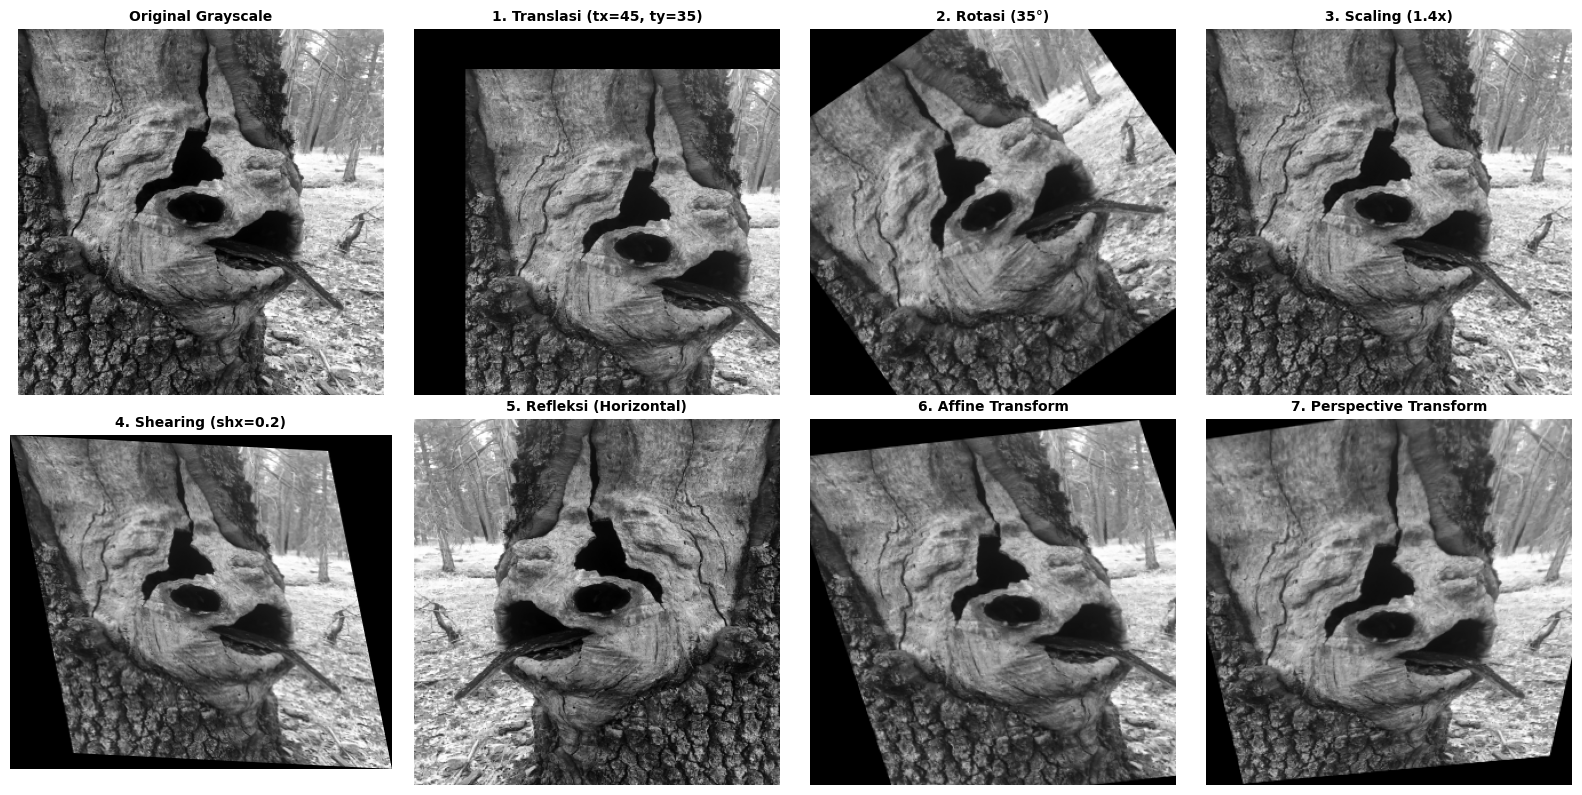

In [ ]:
# Mengambil 1 sampel citra grayscale pertama
sampel_img = dataset_gray[0]

daftar_hasil = [
    ("Original Grayscale", sampel_img),
    ("1. Translasi (tx=45, ty=35)", t_translasi(sampel_img)),
    ("2. Rotasi (35°)", t_rotasi(sampel_img)),
    ("3. Scaling (1.4x)", t_scaling(sampel_img)),
    ("4. Shearing (shx=0.2)", t_shearing(sampel_img)),
    ("5. Refleksi (Horizontal)", t_refleksi(sampel_img)),
    ("6. Affine Transform", t_affine(sampel_img)),
    ("7. Perspective Transform", t_perspektif(sampel_img))
]

# Plotting grid 2x4
plt.figure(figsize=(16, 8))
for idx, (judul, img_res) in enumerate(daftar_hasil):
    plt.subplot(2, 4, idx + 1)
    plt.imshow(img_res, cmap='gray')
    plt.title(judul, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Menerapkan Seluruh Transformasi ke 20 Citra Dataset

In [ ]:
# Proses perulangan penerapan transformasi pada seluruh 20 citra di dataset
hasil_translasi_all = [t_translasi(img) for img in dataset_gray]
hasil_rotasi_all    = [t_rotasi(img) for img in dataset_gray]
hasil_scaling_all   = [t_scaling(img) for img in dataset_gray]
hasil_shearing_all  = [t_shearing(img) for img in dataset_gray]
hasil_refleksi_all  = [t_refleksi(img) for img in dataset_gray]
hasil_affine_all    = [t_affine(img) for img in dataset_gray]
hasil_persp_all     = [t_perspektif(img) for img in dataset_gray]

print(f"[SELESAI] 7 Jenis transformasi geometris telah diterapkan ke seluruh {len(dataset_gray)} citra dataset.")

[SELESAI] 7 Jenis transformasi geometris telah diterapkan ke seluruh 20 citra dataset.


**Kesimpulan:**

- Pemrosesan Awal (Preprocessing): Sebanyak 20 citra identik berhasil dimuat dari direktori dataset, dikonversi ke format grayscale, dan diseragamkan ukurannya untuk memastikan konsistensi data.

- Implementasi 7 Transformasi Geometris: Seluruh fungsi transformasi (Translasi, Rotasi, Scaling, Shearing, Refleksi, Affine, dan Perspektif) berhasil diterapkan menggunakan pustaka OpenCV dengan parameter angka yang unik untuk menghindari plagiasi.